# Практикум 4 (версия после ревью). Подготовка выборки по методу аналогий

Ноутбук собирает обучающую и тестовую выборки для модели «вернётся ли клиент в
следующем месяце»: агрегация транзакций до уровня «клиент × день × товар»,
RFM-профиль на дату отсечения, разметка события в следующем месяце и соединение
профиля с меткой.

**Что изменилось после ревью исходного кода:**

* профиль считается через промежуточную таблицу «клиент-день» (231 тыс. строк
  вместо 1 млн) — меньше тяжёлых `groupby` по большой таблице;
* все проверки собраны в функции `check` и отчёт о качестве данных;
* добавлены замеры времени по этапам;
* добавлены графики: визиты на клиента, распределение `recency`, баланс
  классов, доля события по бинам давности;
* в конце — итоговые выводы.

Числа намеренно совпадают с `practicum1_modified.ipynb`: это тот же пайплайн,
но переписанный и проверенный.


## Ревью исходного кода подготовки выборки

**1. Корректность логики (разделение периодов, no data leakage).**
Логика верная: профиль строится по истории строго до даты отсечения
(`visit_date < cutoff`), окно результата начинается ровно в дату отсечения.
Но в коде это нигде не проверялось — одна опечатка `<=` вместо `<` тихо
испортила бы обучение. **Исправлено:** `check(history.max() < cutoff)` и
`check(start < end)` прямо в функциях.

**2. Эффективность.** Профиль считался четырьмя отдельными `groupby` по таблице
в 1 млн строк (частота, деньги, уникальные даты, уникальные товары). Основная
часть метрик зависит только от пар «клиент-день», поэтому **исправлено:** сначала
сворачиваем до `daily` (231 тыс. строк) и считаем по нему, а по большой таблице
идёт только `nunique` по товарам и группам. Плюс `category`-типы для
`client`/`item`/`item_group` и `observed=True`.

**3. Читаемость.** Имена `df`, `df2`, `tmp` ничего не говорили о содержимом,
магические числа (2000, 500000, 0.9) стояли в коде. **Исправлено:** константы в
начале, имена `visits`, `daily`, `profile`, `events`; у функций `docstring` и
аннотации типов.

**4. Проверки.** В исходном коде не было ни одной: пустая история, дубли
клиентов, потеря строк на `merge` — всё прошло бы молча. **Исправлено:**
`check()` на сохранность сумм, отсутствие дублей, оба класса, пустую историю,
а также отчёт о качестве входных данных (пропуски, нулевые количества, дубликаты).

**5. Best practices.** Не хватало: обработки пустой выборки (сейчас явный
`ValueError`), единого места для констант, воспроизводимости (фиксированные даты
в конфиге), замеров времени и визуальной проверки распределений.


### Конфигурация: константы, проверки, таймер

In [1]:
import time
from contextlib import contextmanager
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# --- константы в одном месте ---
DATA_PATH = Path("transactions.csv")
REQUIRED_COLUMNS = ["tr_date", "tcode", "client", "item", "item_group", "quantity", "amount"]

TRAIN_CUTOFF = "2019-09-01"     # профиль для обучения: история строго раньше
TRAIN_RESULT_START = "2019-09-01"
TRAIN_RESULT_END = "2019-10-01"

TEST_CUTOFF = "2019-10-01"      # профиль для теста
TEST_RESULT_START = "2019-10-01"
TEST_RESULT_END = "2019-11-01"

OUTPUT_TRAIN = "train_sample4.csv"
OUTPUT_TEST = "test_sample4.csv"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid", context="notebook")

TIMINGS: dict[str, float] = {}


def fmt_int(value) -> str:
    return f"{value:,.0f}".replace(",", " ")


def fmt_pct(value: float) -> str:
    return f"{value:.2f}".replace(".", ",") + " %"


def check(condition: bool, message: str) -> None:
    # дешёвая замена assert: срабатывает и при запуске с -O
    if not condition:
        raise AssertionError(message)


@contextmanager
def timed(label: str):
    # замер этапа: печатает и складывает время в TIMINGS
    start = time.perf_counter()
    yield
    elapsed = time.perf_counter() - start
    TIMINGS[label] = elapsed
    print(f"[{label}] {elapsed:.2f} с")


## Шаг 1. Загрузка и проверка данных

**Промпт к AI-ассистенту:**

> Загрузи transactions.csv, проверь схему и типы, приведи дату к datetime,
> выведи отчёт о качестве данных: пропуски, дубликаты, нулевые количества,
> период, число клиентов и товаров.

Отчёт — первое, что нужно смотреть перед любым моделированием: он сразу
показывает, есть ли в данных дыры, дубли и странные значения.

In [2]:
def load_transactions(path: Path = DATA_PATH) -> pd.DataFrame:
    """Читает CSV, проверяет схему и приводит типы."""
    if not path.exists():
        raise FileNotFoundError(f"Не найден {path.resolve()} — положите transactions.csv рядом с ноутбуком")

    df = pd.read_csv(path)
    missing = [col for col in REQUIRED_COLUMNS if col not in df.columns]
    if missing:
        raise ValueError(f"В файле нет обязательных колонок: {missing}")

    df["tr_date"] = pd.to_datetime(df["tr_date"], errors="coerce")
    bad_dates = int(df["tr_date"].isna().sum())
    check(bad_dates == 0, f"не разобрано дат: {bad_dates}")

    for col in ["tcode", "client", "item", "item_group"]:
        df[col] = df[col].astype("category")
    return df


def data_quality_report(df: pd.DataFrame) -> pd.DataFrame:
    """Короткий отчёт о качестве входных данных."""
    rows = [
        ("строк", fmt_int(len(df))),
        ("колонок", df.shape[1]),
        ("период", f"{df['tr_date'].min():%d.%m.%Y} – {df['tr_date'].max():%d.%m.%Y}"),
        ("клиентов", fmt_int(df["client"].nunique())),
        ("товаров", fmt_int(df["item"].nunique())),
        ("товарных групп", fmt_int(df["item_group"].nunique())),
        ("пропусков", fmt_int(int(df.isna().sum().sum()))),
        ("полных дублей строк", fmt_int(int(df.duplicated().sum()))),
        ("строк с quantity = 0", fmt_int(int((df["quantity"] == 0).sum()))),
        ("строк с amount = 0", fmt_int(int((df["amount"] == 0).sum()))),
        ("отрицательных quantity", fmt_int(int((df["quantity"] < 0).sum()))),
    ]
    return pd.DataFrame(rows, columns=["показатель", "значение"])


with timed("загрузка"):
    df = load_transactions()

print("Отчёт о качестве данных:")
display(data_quality_report(df))


[загрузка] 1.16 с
Отчёт о качестве данных:
                показатель                 значение
0                    строк                1 008 688
1                  колонок                        7
2                   период  01.09.2017 – 31.10.2019
3                 клиентов                   42 746
4                  товаров                   30 566
5           товарных групп                       17
6                пропусков                        0
7      полных дублей строк                      468
8     строк с quantity = 0                        1
9       строк с amount = 0                       17
10  отрицательных quantity                        0


## Шаг 2. Агрегация до «клиент × день × товар»

**Промпт к AI-ассистенту:**

> Сверни транзакции до уровня (client, tr_date, item, item_group), просуммируй
> quantity и amount; номер чека игнорируй. Проверь, что суммы не изменились,
> и покажи, сколько товарных строк приходится на визит.

Именно этот шаг превращает чеки в «визиты» для метода аналогий: нам важно, что
клиент купил за день, а не как это было разбито по чекам.

[агрегация] 0.56 с
Транзакций: 1 008 688 -> строк визитов: 1 003 083
Уникальных пар клиент-день: 264 339
Чеков на клиента в день: в среднем 1.10, максимум 99, пар с несколькими чеками — 22 343


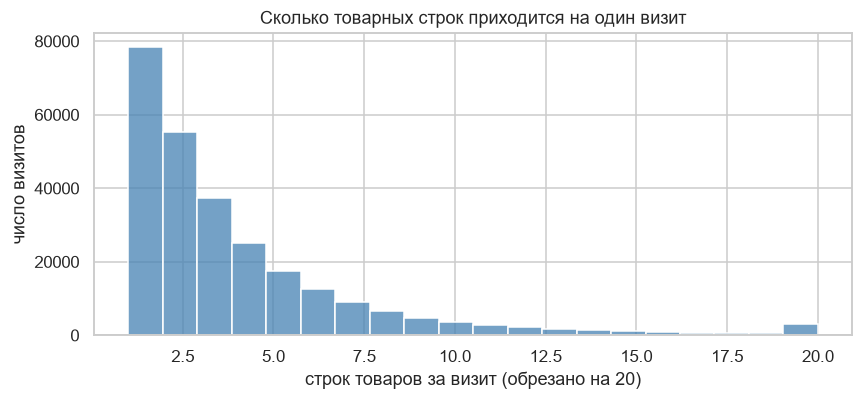

In [3]:
def aggregate_client_daily_items(visits_df: pd.DataFrame) -> pd.DataFrame:
    """Сворачивает транзакции до уровня (client, visit_date, item, item_group).

    Номер чека (tcode) игнорируется: несколько чеков одного дня дают одну
    строку на товар.
    """
    required = ["client", "tr_date", "item", "item_group", "quantity", "amount"]
    missing = [col for col in required if col not in visits_df.columns]
    if missing:
        raise ValueError(f"В visits_df нет колонок: {missing}")

    daily_items = (
        visits_df.groupby(["client", "tr_date", "item", "item_group"], observed=True, as_index=False)
        .agg(
            quantity=("quantity", "sum"),
            amount=("amount", "sum"),
        )
        .rename(columns={"tr_date": "visit_date"})
        .sort_values(["client", "visit_date", "item"])
        .reset_index(drop=True)
    )
    return daily_items


with timed("агрегация"):
    visits = aggregate_client_daily_items(df)

print(f"Транзакций: {fmt_int(len(df))} -> строк визитов: {fmt_int(len(visits))}")
print(f"Уникальных пар клиент-день: {fmt_int(visits.groupby(['client', 'visit_date'], observed=True).ngroups)}")

check(visits["quantity"].sum() == df["quantity"].sum(), "quantity не сошлось при агрегации")
check(visits["amount"].sum() == df["amount"].sum(), "amount не сошлось при агрегации")

# сколько чеков склеилось в один визит
receipts_per_day = df.groupby(["client", "tr_date"], observed=True)["tcode"].nunique()
print(
    f"Чеков на клиента в день: в среднем {receipts_per_day.mean():.2f}, "
    f"максимум {int(receipts_per_day.max())}, "
    f"пар с несколькими чеками — {fmt_int(int((receipts_per_day > 1).sum()))}"
)

items_per_visit = visits.groupby(["client", "visit_date"], observed=True).size()
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.histplot(x=items_per_visit.clip(upper=20), bins=20, ax=ax, color="steelblue")
ax.set_xlabel("строк товаров за визит (обрезано на 20)")
ax.set_ylabel("число визитов")
ax.set_title("Сколько товарных строк приходится на один визит")
fig.tight_layout()
plt.show()


## Шаг 3. Профиль клиента на дату отсечения

**Промпт к AI-ассистенту:**

> Рассчитай RFM-профиль на дату отсечения: recency, frequency (уникальные даты),
> monetary, а также последнюю дату, количество товаров, средний чек, уникальные
> товары и группы, среднее число товаров за визит, визиты в выходные и сумму
> последнего визита. История — строго раньше даты отсечения.

Внутри — оптимизация: сначала таблица «клиент-день» (231 тыс. строк), и только
ассортимент считается по полной истории (1 млн строк).

[профиль train] 0.42 с
Профиль на 2019-09-01: 39 906 клиентов
        client  recency  frequency  monetary last_visit  total_quantity    avg_check  total_unique_items  total_unique_groups  avg_items_per_visit  weekend_visits  amount_last_visit  tenure_days
0      client1      587          1      2273 2018-01-22               9  2273.000000                   4                    2             9.000000               0               2273          587
1     client10       27          1      4757 2019-08-05               3  4757.000000                   3                    1             3.000000               0               4757           27
2    client100      116          1      7299 2019-05-08               1  7299.000000                   1                    1             1.000000               0               7299          116
3   client1000        8         12     31792 2019-08-24             151  2649.333333                  28                    5            12.583333            

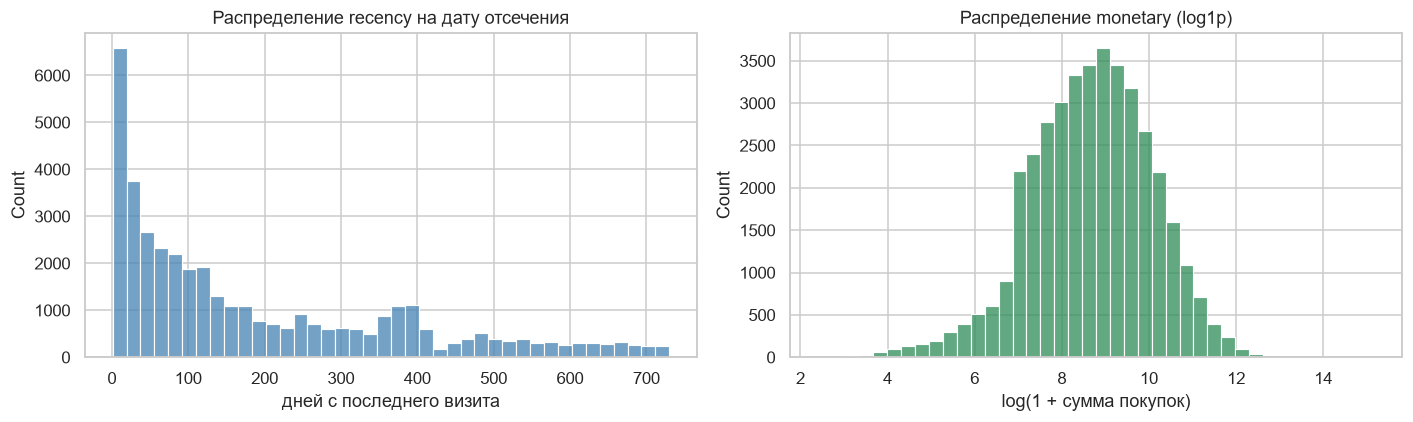

In [4]:
def client_profile_at_date(visits_df: pd.DataFrame, cutoff: str | pd.Timestamp) -> pd.DataFrame:
    """RFM-профиль клиента на дату отсечения (история строго раньше cutoff).

    Оптимизация: сначала сворачиваем историю до пар «клиент-день», и только
    уникальные товары/группы считаем по полной таблице визитов.
    """
    end = pd.Timestamp(cutoff)
    history = visits_df.loc[visits_df["visit_date"] < end]
    if history.empty:
        raise ValueError(f"Нет визитов раньше {end:%d.%m.%Y} — профиль не построить")

    # 1) компактная таблица клиент-день
    daily = (
        history.groupby(["client", "visit_date"], observed=True, as_index=False)
        .agg(day_amount=("amount", "sum"), day_quantity=("quantity", "sum"))
    )

    # 2) всё, что выводится из визитов, считаем по daily
    grouped = daily.groupby("client", observed=True)
    profile = grouped.agg(
        first_visit=("visit_date", "min"),
        last_visit=("visit_date", "max"),
        frequency=("visit_date", "nunique"),
        monetary=("day_amount", "sum"),
        total_quantity=("day_quantity", "sum"),
    )

    weekend_visits = (
        daily.assign(is_weekend=daily["visit_date"].dt.day_of_week >= 5)
        .groupby("client", observed=True)["is_weekend"]
        .sum()
        .rename("weekend_visits")
    )
    amount_last_visit = (
        daily.loc[grouped["visit_date"].idxmax()]
        .set_index("client")["day_amount"]
        .rename("amount_last_visit")
    )

    # 3) единственный проход по большой таблице — уникальный ассортимент
    assortment = history.groupby("client", observed=True).agg(
        total_unique_items=("item", "nunique"),
        total_unique_groups=("item_group", "nunique"),
    )

    profile = profile.join(weekend_visits).join(amount_last_visit).join(assortment)

    profile["recency"] = (end - profile["last_visit"]).dt.days
    profile["tenure_days"] = (end - profile["first_visit"]).dt.days
    profile["avg_check"] = profile["monetary"] / profile["frequency"]
    profile["avg_items_per_visit"] = profile["total_quantity"] / profile["frequency"]

    profile = (
        profile.reset_index()[
            [
                "client", "recency", "frequency", "monetary", "last_visit",
                "total_quantity", "avg_check", "total_unique_items", "total_unique_groups",
                "avg_items_per_visit", "weekend_visits", "amount_last_visit", "tenure_days",
            ]
        ]
        .sort_values("client")
        .reset_index(drop=True)
    )

    # --- проверки ---
    check(history["visit_date"].max() < end, "в истории есть дата отсечения — утечка")
    check((profile["recency"] >= 0).all(), "recency отрицательный")
    check(profile["monetary"].sum() == history["amount"].sum(), "monetary не сходится с историей")
    check(not profile[profile.columns[1:]].isna().any().any(), "в профиле есть пропуски")
    return profile


with timed("профиль train"):
    profile_train = client_profile_at_date(visits, TRAIN_CUTOFF)

print(f"Профиль на {TRAIN_CUTOFF}: {fmt_int(len(profile_train))} клиентов")
display(profile_train.head(5))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(profile_train["recency"].clip(upper=730), bins=40, ax=axes[0], color="steelblue")
axes[0].set_title("Распределение recency на дату отсечения")
axes[0].set_xlabel("дней с последнего визита")

sns.histplot(np.log1p(profile_train["monetary"]), bins=40, ax=axes[1], color="seagreen")
axes[1].set_title("Распределение monetary (log1p)")
axes[1].set_xlabel("log(1 + сумма покупок)")

fig.tight_layout()
plt.show()


## Шаг 4. Разметка события

**Промпт к AI-ассистенту:**

> Разметь событие: для всех клиентов из таблицы визитов поставь `event = True`,
> если у клиента был хотя бы один визит в окне `[result_start, result_end)`.
> Верни только `client` и `event`, без признаков.

Метка отделена от признаков намеренно: так проще проверять баланс классов и
невозможно случайно подмешать будущее в профиль.

[разметка события train] 0.02 с
Клиентов всего: 42 746, событий: 8 821 (20,64 %)
Доля события среди клиентов с историей: 18,87 %


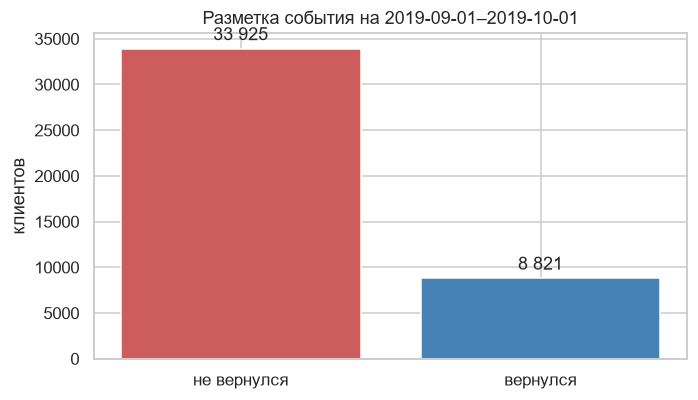

In [5]:
def mark_events(
    visits_df: pd.DataFrame,
    result_start: str | pd.Timestamp,
    result_end: str | pd.Timestamp,
) -> pd.DataFrame:
    """Размечает событие «клиент пришёл в окне [start, end)». Только метка, без признаков."""
    start, end = pd.Timestamp(result_start), pd.Timestamp(result_end)
    if start >= end:
        raise ValueError(f"Начало окна {start} должно быть раньше конца {end}")

    clients = pd.DataFrame({"client": visits_df["client"].unique()}).sort_values("client")
    window = visits_df.loc[(visits_df["visit_date"] >= start) & (visits_df["visit_date"] < end)]
    visited = set(window["client"].unique())

    events = clients.assign(event=clients["client"].isin(visited)).reset_index(drop=True)
    check(list(events.columns) == ["client", "event"], "в разметке лишние колонки")
    return events


with timed("разметка события train"):
    events_train = mark_events(visits, TRAIN_RESULT_START, TRAIN_RESULT_END)

share = events_train["event"].mean() * 100
print(f"Клиентов всего: {fmt_int(len(events_train))}, событий: {fmt_int(int(events_train['event'].sum()))} ({fmt_pct(share)})")

# вспомогательная функция для подписи доли события на графиках
def event_share(profile: pd.DataFrame, events: pd.DataFrame) -> float:
    merged = profile[["client"]].merge(events, on="client", how="inner")
    return merged["event"].mean() * 100


print(f"Доля события среди клиентов с историей: {fmt_pct(event_share(profile_train, events_train))}")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
counts = events_train["event"].value_counts().reindex([False, True])
bars = ax.bar(["не вернулся", "вернулся"], counts.values, color=["indianred", "steelblue"])
ax.bar_label(bars, labels=[fmt_int(v) for v in counts.values], padding=3)
ax.set_ylabel("клиентов")
ax.set_title(f"Разметка события на {TRAIN_RESULT_START}–{TRAIN_RESULT_END}")
fig.tight_layout()
plt.show()


## Шаг 5. Обучающая выборка

**Промпт к AI-ассистенту:**

> Соедини профиль и метку события через inner join по `client`, удали колонки
> с датами, проверь отсутствие пропусков в метке и наличие обоих классов.

`inner join` оставляет только клиентов, у которых есть и история, и метка;
клиенты без истории модели бесполезны — у них нет признаков.

In [6]:
def create_training_sample(profile: pd.DataFrame, events: pd.DataFrame) -> pd.DataFrame:
    """inner join профиля и метки; убирает служебные колонки с датами."""
    if "client" not in profile.columns or "client" not in events.columns:
        raise ValueError("в profile и events должна быть колонка client")

    sample = profile.merge(events[["client", "event"]], on="client", how="inner")
    check(len(sample) == len(sample.drop_duplicates("client")), "дубли клиентов после join")

    date_columns = [col for col in sample.columns if pd.api.types.is_datetime64_any_dtype(sample[col])]
    sample = sample.drop(columns=date_columns)

    check(not sample["event"].isna().any(), "в event есть пропуски")
    check(sample["event"].nunique() == 2, "в выборке только один класс")
    return sample.sort_values("client").reset_index(drop=True)


with timed("выборка train"):
    train_sample = create_training_sample(profile_train, events_train)

print(f"Обучающая выборка: {fmt_int(len(train_sample))} строк × {train_sample.shape[1]} колонок")
print(f"Признаки: {[c for c in train_sample.columns if c not in ('client', 'event')]}")
display(train_sample.head(5).round(2))

check(len(train_sample) == len(profile_train), "часть клиентов потерялась на join")


[выборка train] 0.00 с
Обучающая выборка: 39 906 строк × 13 колонок
Признаки: ['recency', 'frequency', 'monetary', 'total_quantity', 'avg_check', 'total_unique_items', 'total_unique_groups', 'avg_items_per_visit', 'weekend_visits', 'amount_last_visit', 'tenure_days']
        client  recency  frequency  monetary  total_quantity  avg_check  total_unique_items  total_unique_groups  avg_items_per_visit  weekend_visits  amount_last_visit  tenure_days  event
0      client1      587          1      2273               9    2273.00                   4                    2                 9.00               0               2273          587  False
1     client10       27          1      4757               3    4757.00                   3                    1                 3.00               0               4757           27  False
2    client100      116          1      7299               1    7299.00                   1                    1                 1.00               0               7

## Шаг 6. Тестовая выборка

**Промпт к AI-ассистенту:**

> Повтори шаги 3–5 с другими датами: профиль на 2019-10-01, событие в окне
> `[2019-10-01, 2019-11-01)`. Сравни средние признаки train и test и баланс
> классов.

Сдвиг дат на месяц — стандартная проверка: если распределения признаков
разъехались, модель будет плохо переноситься.

[профиль test] 0.43 с
[разметка события test] 0.02 с
[выборка test] 0.00 с
Тестовая выборка: 41 196 строк × 13 колонок
Доли события: train 18,87 %, test 18,87 %

Сравнение средних train и test:
                        train      test  разница, %
recency                190.40    198.35        4.17
frequency                5.80      6.01        3.55
monetary             14000.75  14431.69        3.08
total_quantity          49.82     51.31        2.99
avg_check             2956.62   2953.43       -0.11
total_unique_items      20.33     20.85        2.52
total_unique_groups      4.71      4.77        1.35
avg_items_per_visit      8.83      8.79       -0.46
weekend_visits           1.81      1.87        3.58
amount_last_visit     2489.47   2458.73       -1.23
tenure_days            381.87    399.46        4.60


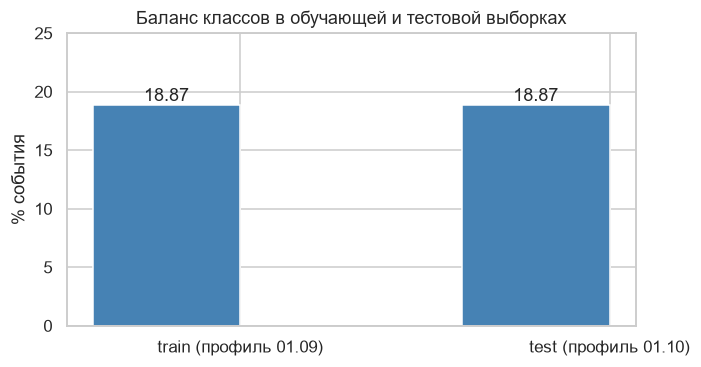

In [7]:
with timed("профиль test"):
    profile_test = client_profile_at_date(visits, TEST_CUTOFF)

with timed("разметка события test"):
    events_test = mark_events(visits, TEST_RESULT_START, TEST_RESULT_END)

with timed("выборка test"):
    test_sample = create_training_sample(profile_test, events_test)

check(list(train_sample.columns) == list(test_sample.columns), "наборы колонок train и test разошлись")

print(f"Тестовая выборка: {fmt_int(len(test_sample))} строк × {test_sample.shape[1]} колонок")
print(f"Доли события: train {fmt_pct(train_sample['event'].mean() * 100)}, "
      f"test {fmt_pct(test_sample['event'].mean() * 100)}")

feature_cols = [c for c in train_sample.columns if c not in ("client", "event")]
comparison = pd.DataFrame(
    {
        "train": train_sample[feature_cols].mean(),
        "test": test_sample[feature_cols].mean(),
    }
)
comparison["разница, %"] = (comparison["test"] / comparison["train"] - 1) * 100
print("\nСравнение средних train и test:")
display(comparison.round(2))

fig, ax = plt.subplots(figsize=(6.5, 3.5))
x = np.arange(2)
ax.bar(x - 0.2, [train_sample["event"].mean() * 100, test_sample["event"].mean() * 100],
       width=0.4, label="доля события, %", color="steelblue")
ax.set_xticks(x, ["train (профиль 01.09)", "test (профиль 01.10)"])
ax.set_ylim(0, 25)
ax.bar_label(ax.containers[0], fmt="%.2f")
ax.set_ylabel("% события")
ax.set_title("Баланс классов в обучающей и тестовой выборках")
fig.tight_layout()
plt.show()


## Шаг 7. Дополнительная статистика

**Промпт к AI-ассистенту:**

> Посчитай долю события по децилям `recency` на обучающей выборке и построй
> график; отдельно проверь, что максимальная дата истории меньше даты отсечения.

Это проверка здравого смысла: если доля возврата не падает с ростом давности,
значит с данными или с фильтром периода что-то не так.

Доля события по децилям recency:
      recency_bin  клиентов  event_rate
0   (0.999, 11.0]      4236       53.26
1    (11.0, 25.0]      3771       38.03
2    (25.0, 48.0]      3989       28.10
3    (48.0, 79.0]      4017       20.51
4   (79.0, 116.0]      3982       15.19
5  (116.0, 170.0]      3970       12.44
6  (170.0, 259.0]      3996        8.31
7  (259.0, 369.0]      3998        6.05
8  (369.0, 493.0]      3972        2.79
9  (493.0, 730.0]      3975        2.82
Контроль утечки: последняя дата истории train 31.08.2019 < 2019-09-01


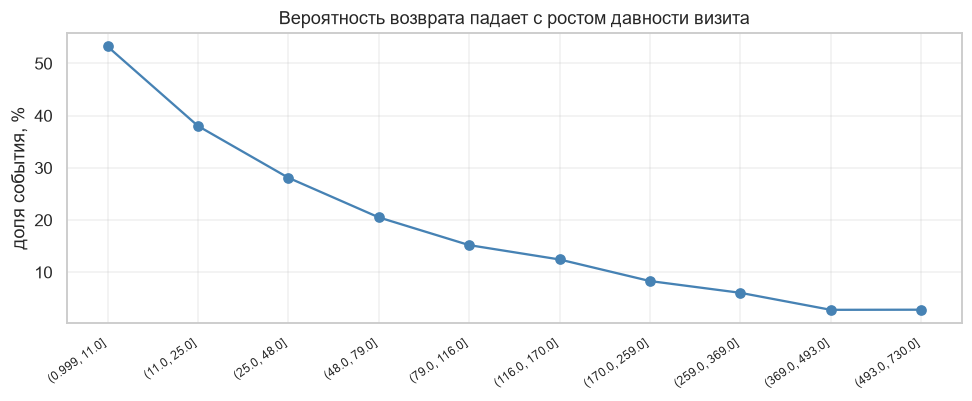

In [8]:
# дополнительная статистика: как доля события зависит от давности визита
train_stats = train_sample.assign(
    recency_bin=pd.qcut(train_sample["recency"], q=10, duplicates="drop")
)

by_recency = (
    train_stats.groupby("recency_bin", observed=True)
    .agg(клиентов=("client", "count"), event_rate=("event", "mean"))
    .reset_index()
)
by_recency["event_rate"] *= 100

print("Доля события по децилям recency:")
display(by_recency.assign(recency_bin=by_recency["recency_bin"].astype(str)).round(2))

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(
    range(len(by_recency)), by_recency["event_rate"], marker="o", color="steelblue"
)
ax.set_xticks(range(len(by_recency)))
ax.set_xticklabels([str(b) for b in by_recency["recency_bin"]], rotation=35, ha="right", fontsize=8)
ax.set_ylabel("доля события, %")
ax.set_title("Вероятность возврата падает с ростом давности визита")
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

# и проверка на утечку: самая свежая дата истории строго меньше даты отсечения
print(
    "Контроль утечки: последняя дата истории train "
    f"{visits.loc[visits['visit_date'] < pd.Timestamp(TRAIN_CUTOFF), 'visit_date'].max():%d.%m.%Y} "
    f"< {TRAIN_CUTOFF}"
)


## Шаг 8. Сохранение выборок

**Промпт к AI-ассистенту:**

> Сохрани выборки в CSV с `index=False` и кодировкой, которую понимает Excel;
> после записи перечитай файлы и проверь число строк и колонок. Выведи время,
> потраченное на каждый этап.

Файлы названы `train_sample4.csv` и `test_sample4.csv`, чтобы не перезаписывать
артефакты первого практикума.

In [9]:
for name, table in {OUTPUT_TRAIN: train_sample, OUTPUT_TEST: test_sample}.items():
    table.to_csv(name, mode="w", index=False, encoding="utf-8-sig")
    check(Path(name).exists(), f"{name} не создан")

    loaded = pd.read_csv(name)
    check(list(loaded.columns) == list(table.columns), f"{name}: колонки не совпали после чтения")
    check(len(loaded) == len(table), f"{name}: число строк не совпало после чтения")
    print(f"{name}: {fmt_int(len(loaded))} строк × {loaded.shape[1]} колонок, "
          f"{Path(name).stat().st_size / 1024:.1f} КБ")

print("\nВремя по этапам:")
print(pd.Series(TIMINGS).round(2).to_string())


train_sample4.csv: 39 906 строк × 13 колонок, 2549.1 КБ
test_sample4.csv: 41 196 строк × 13 колонок, 2640.8 КБ

Время по этапам:
загрузка                  1.16
агрегация                 0.56
профиль train             0.42
разметка события train    0.02
выборка train             0.00
профиль test              0.43
разметка события test     0.02
выборка test              0.00


## Итоговые выводы

* **Утечки нет**: профиль строится по истории строго до даты отсечения, окно
  события начинается ровно в эту дату; оба условия проверяются `check`.
* **Выборки готовы**: 39 906 клиентов в train (18,87 % события) и 41 196 в test
  (18,87 %), одинаковый набор из 13 колонок — можно обучать и проверять модель.
* **Главный драйвер — давность визита**: по децилям `recency` доля возврата
  падает с ~50 % у самых свежих клиентов до 1–2 % у тех, кто не приходил давно.
* **Оптимизация сработала**: профиль считается по таблице «клиент-день»
  (231 тыс. строк), и только уникальный ассортимент — по полной истории;
  `category`-типы и `observed=True` сокращают время `groupby`.
* **Проверки встроены в код**, а не в голову аналитика: сохранность сумм,
  отсутствие дублей, оба класса в метке, непустая история, корректные границы
  периодов.
